In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

crash_summary_2019= pd.read_csv("CrashMap_data(2019).csv", low_memory=False)
print(crash_summary_2019.shape)
crash_summary_2019.head()


FileNotFoundError: [Errno 2] No such file or directory: 'CrashMap_data(2019).csv'

In [5]:
import os
print(os.getcwd())   # shows where the notebook is running


/home/ashleeyy/cmsc320Fall/Semester_Project/maryland-precipitation-crashes


In [7]:
#combine all the datasets together

RAW = "maryland_crash_data/raw"

data = {}
for y in years:
    data[y] = pd.read_csv(f"{RAW}/CrashMap_REPORT_{y}.csv", low_memory=False)
    data[y]["Crashdate"] = pd.to_datetime(data[y]["Crashdate"], errors="coerce")
    print(y, data[y].shape,
          data[y]["Crashdate"].min().date(), "to", data[y]["Crashdate"].max().date(),
          "| unique reports:", data[y]["Reportnumber"].nunique())

2019 (116087, 9) 2019-01-01 to 2019-12-31 | unique reports: 116087
2020 (95714, 9) 2020-01-01 to 2020-12-31 | unique reports: 95714
2021 (108969, 9) 2021-01-01 to 2021-12-31 | unique reports: 108969
2022 (108600, 9) 2022-01-01 to 2022-12-31 | unique reports: 108600
2023 (110472, 9) 2023-01-01 to 2023-12-31 | unique reports: 110472


In [8]:
#stack the datasets together

df=pd.concat(data.values(), ignore_index=True)

print(df.shape)
print(df["Reportnumber"].duplicated().sum())
df["year"]=df["Crashdate"].dt.year
print(df["year"].value_counts().sort_index())

df.to_csv("MD_crashes_2019_2023.csv", index=False)

(539842, 9)
0
year
2019    116087
2020     95714
2021    108969
2022    108600
2023    110472
Name: count, dtype: int64


In [10]:
print(df["UseData"].value_counts(dropna=False).head(10))
print(df["Reporttype"].value_counts(dropna=False))
print(df["CountyOfCrash"].value_counts(dropna=False))
print(df.isna().mean().round(3))
print(df[["Latitude", "Longitude"]].describe())

UseData
True    539842
Name: count, dtype: int64
Reporttype
Property Damage Crash    393470
Injury Crash             143596
Fatal Crash                2776
Name: count, dtype: int64
CountyOfCrash
Baltimore          100876
Prince George's     98172
Baltimore City      84181
Montgomery          60099
Anne Arundel        47896
Howard              18853
Frederick           16654
Harford             16063
Charles             14082
Washington          12393
Wicomico            10498
Carroll              9501
Cecil                8248
St. Mary's           8140
Worcester            6863
Calvert              5200
Queen Anne's         4043
Talbot               3851
Allegany             3714
Dorchester           2717
Caroline             2513
Garrett              2467
Somerset             1616
Kent                 1202
Name: count, dtype: int64
Reportnumber     0.0
AgencyCode       0.0
CountyOfCrash    0.0
Reporttype       0.0
UseData          0.0
Crashdate        0.0
CrashPoint       0.0
Latitud

In [11]:
#get rid of bad coordinates
in_md=df["Latitude"].between(37.9, 39.73) & df["Longitude"].between(-79.5, -75.0)
df.loc[~in_md & df["Latitude"].notna(), ["Reportnumber", "CountyOfCrash", "Latitude", "Longitude"]].head(20)

df=df.drop(columns=["UseData", "CrashPoint"])

df["Latitude"]= df["Latitude"].where(in_md)
df["Longitude"]=df["Longitude"].where(in_md)

In [ ]:
df["Crashdate"]= pd.to_datetime(df["Crashdate"], errors="coerce")
df["year"]= df["Crashdate"].dt.year
df["month"]= df["Crashdate"].dt.month

type_map={
    "Property Damage Crash": "property_damage_crashes",
    "Injury Crash": "injury_crashes",
    "Fatal Crash": "fatal_crashes",
}

df["crash_type"]= df["Reporttype"].map(type_map)

monthly=(
    df.groupby(["CountyOfCrash", "year", "month", "crash_type"])
    .size().unstack("crash_type", fill_value=0).reset_index().rename(columns={"CountyOfCrash": "county"})
)

countries= monthly["county"].unique()
full= pd.MultiIndex.from_product([countries, range(2019,2024), range(1,13)], names=["county", "year", "month"])
monthly= (monthly.set_index(["county", "year", "month"]).reindex(full, fill_value=0).reset_index())

monthly["total_crashes"]=(monthly["property_damage_crashes"]+monthly["injury_crashes"]+monthly["fatal_crashes"])
monthly["injury_or_fatal_crashes"]= monthly["injury_crashes"]+monthly["fatal_crashes"]

monthly["year_month"]=pd.to_datetime(dict(year=monthly.year, month=monthly.month, day=1))
monthly["days_in_month"]= monthly["year_month"].dt.days_in_month
monthly["crashes_per_day"]=(monthly["total_crashes"]/monthly["days_in_month"]).round(2)

monthly.to_csv("maryland_crash_data/cleaned/md_crashes_by_county_month.csv", index=False)

In [13]:
print(monthly.shape)
print(monthly["total_crashes"].sum())
print(monthly["county"].nunique())
print(monthly.groupby("year")["total_crashes"].sum())

(1440, 11)
539842
24
year
2019    116087
2020     95714
2021    108969
2022    108600
2023    110472
Name: total_crashes, dtype: int64


In [14]:
monthly= monthly.sort_values(["county", "year", "month"]).reset_index(drop=True)
monthly.head(12)
print(monthly.dtypes)
print((monthly["total_crashes"]==0).sum())

crash_type
county                                str
year                                int32
month                               int32
fatal_crashes                       int64
injury_crashes                      int64
property_damage_crashes             int64
total_crashes                       int64
injury_or_fatal_crashes             int64
year_month                 datetime64[us]
days_in_month                       int32
crashes_per_day                   float64
dtype: object
0


In [15]:
print(sorted(monthly["county"].unique()))

['Allegany', 'Anne Arundel', 'Baltimore', 'Baltimore City', 'Calvert', 'Caroline', 'Carroll', 'Cecil', 'Charles', 'Dorchester', 'Frederick', 'Garrett', 'Harford', 'Howard', 'Kent', 'Montgomery', "Prince George's", "Queen Anne's", 'Somerset', "St. Mary's", 'Talbot', 'Washington', 'Wicomico', 'Worcester']


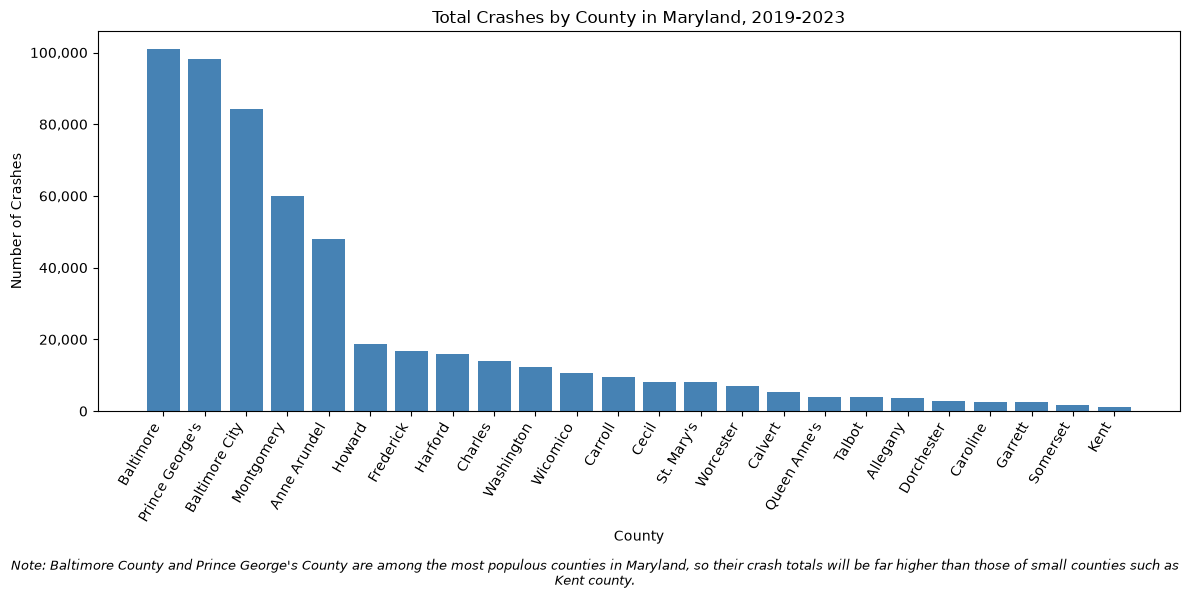

In [16]:
#graph

by_county= (monthly.groupby("county")["total_crashes"].sum().sort_values(ascending=False))

fig, ax=plt.subplots(figsize=(12,6))
ax.bar(by_county.index, by_county.values, color="Steelblue")

ax.set_title("Total Crashes by County in Maryland, 2019-2023")
ax.set_xlabel("County")
ax.set_ylabel("Number of Crashes")
ax.set_xticks(range(len(by_county)))
ax.set_xticklabels(by_county.index, rotation=60, ha="right")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _:f"{int(x):,}"))

note=("Note: Baltimore County and Prince George's County are among the most populous counties in Maryland, so their crash totals will be far higher than those of small counties such as Kent county.")
fig.text(0.5, 0.01, note, ha="center", va="bottom", fontsize=9, style="italic", wrap=True)

plt.tight_layout(rect=[0,0.06,1,1])
plt.savefig("crashes_by_county.png", dpi=200)
plt.show()

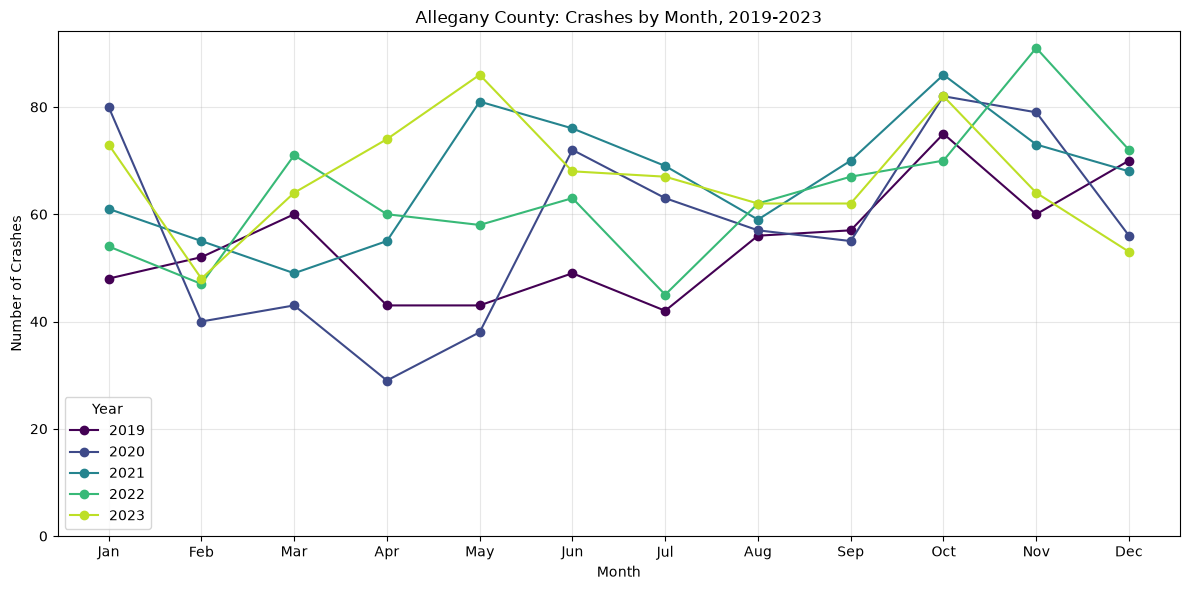

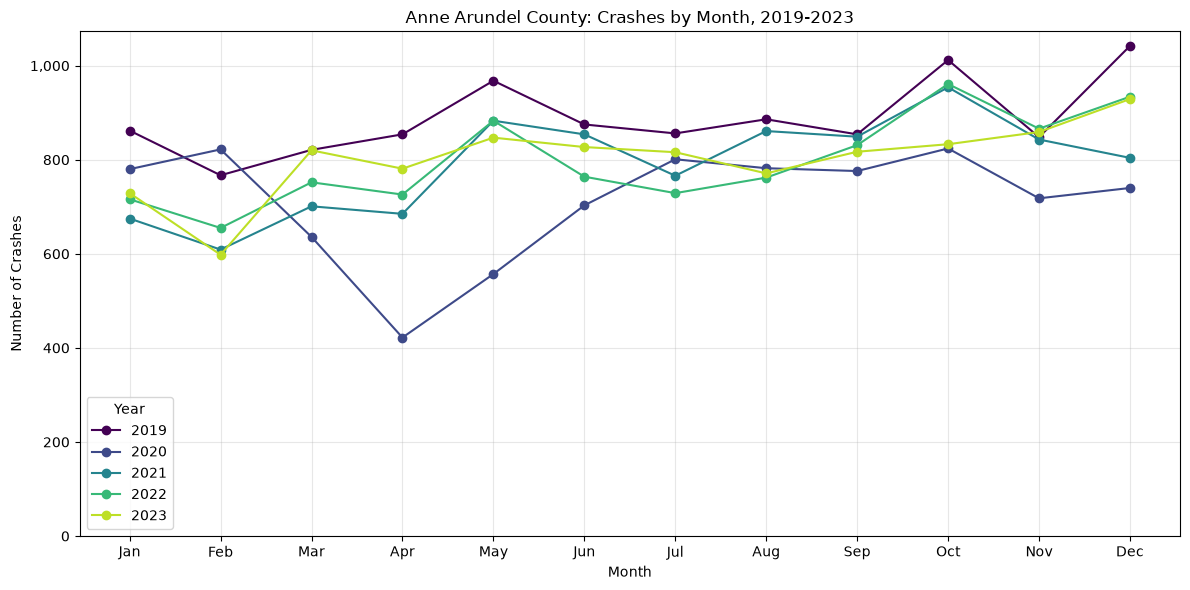

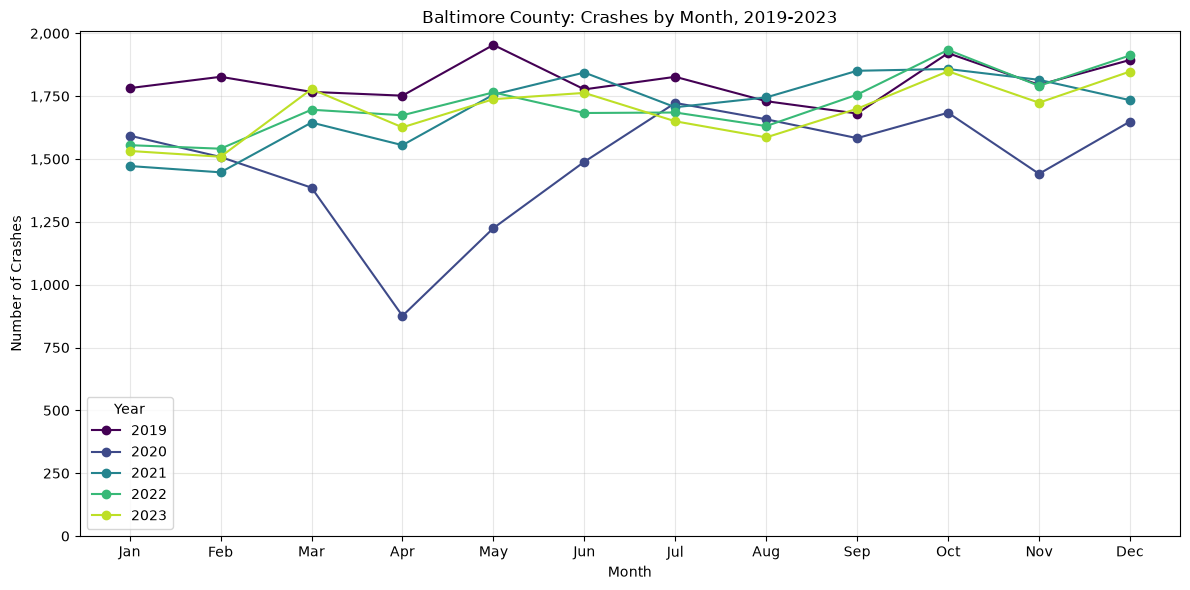

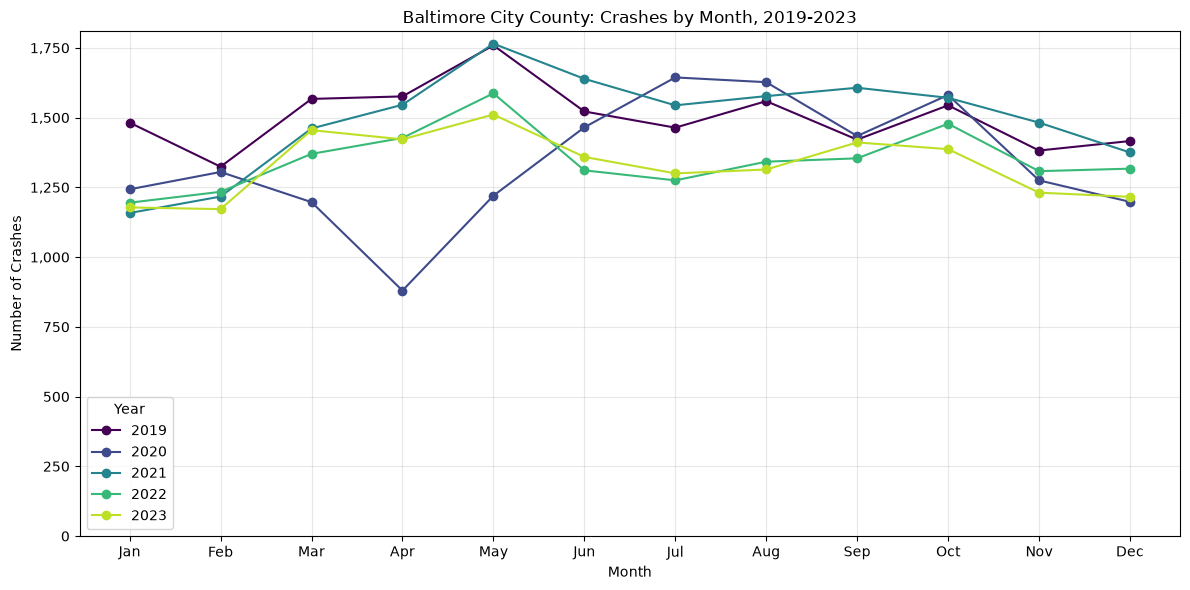

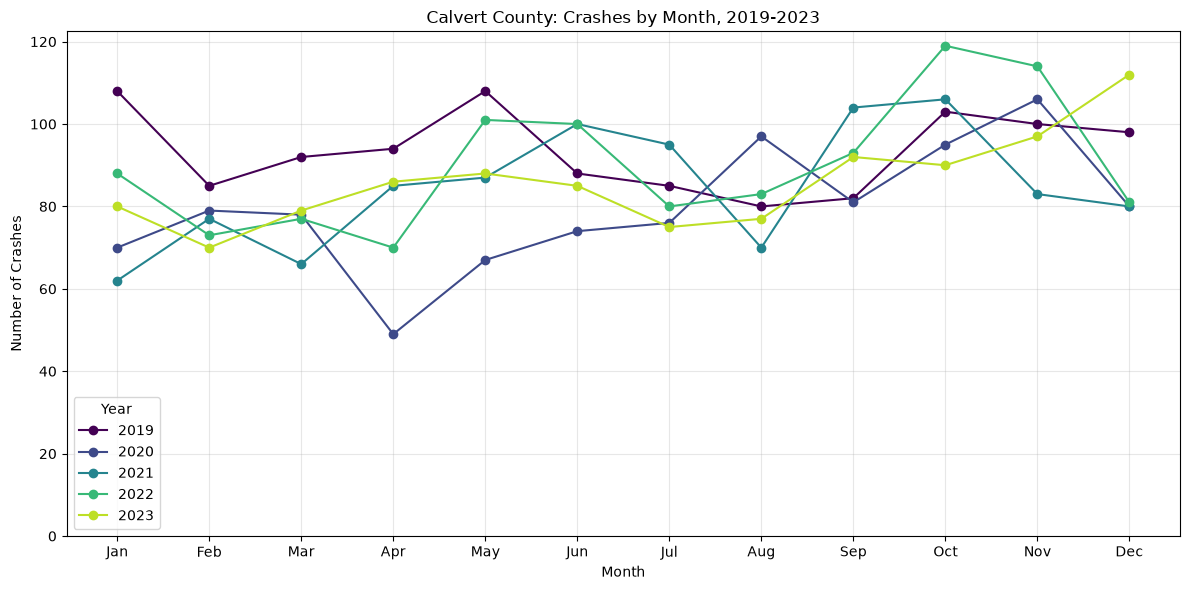

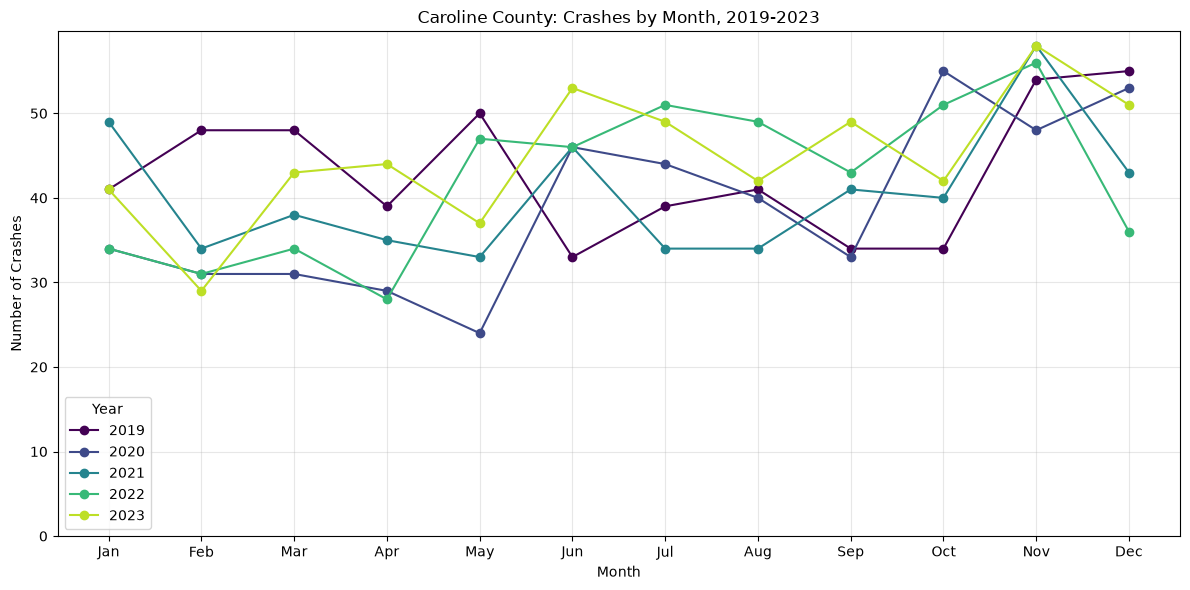

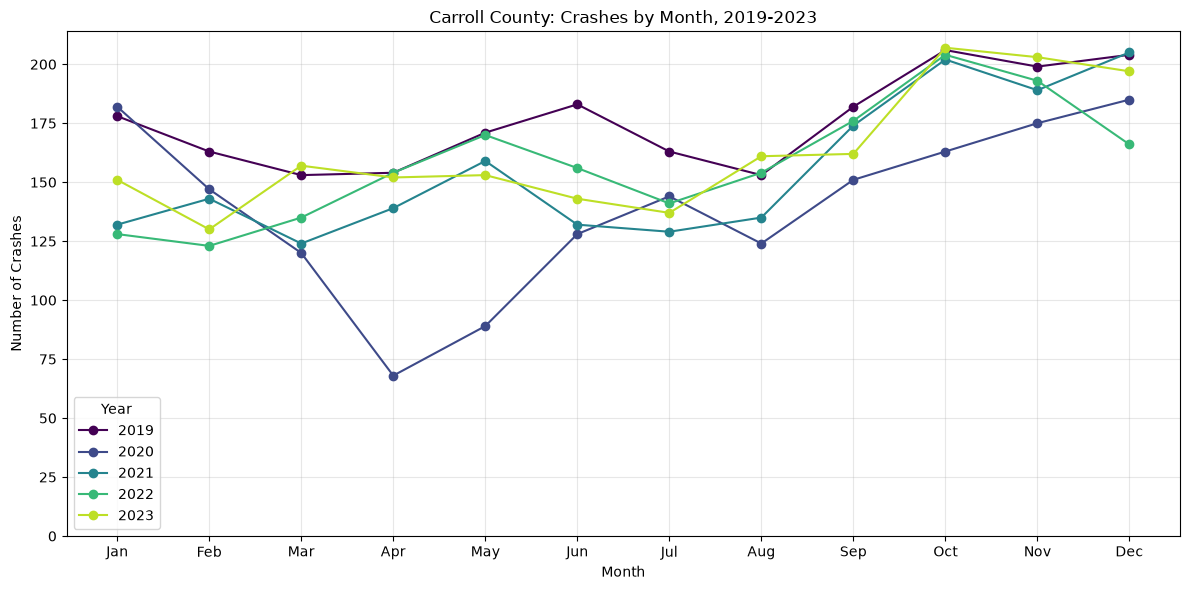

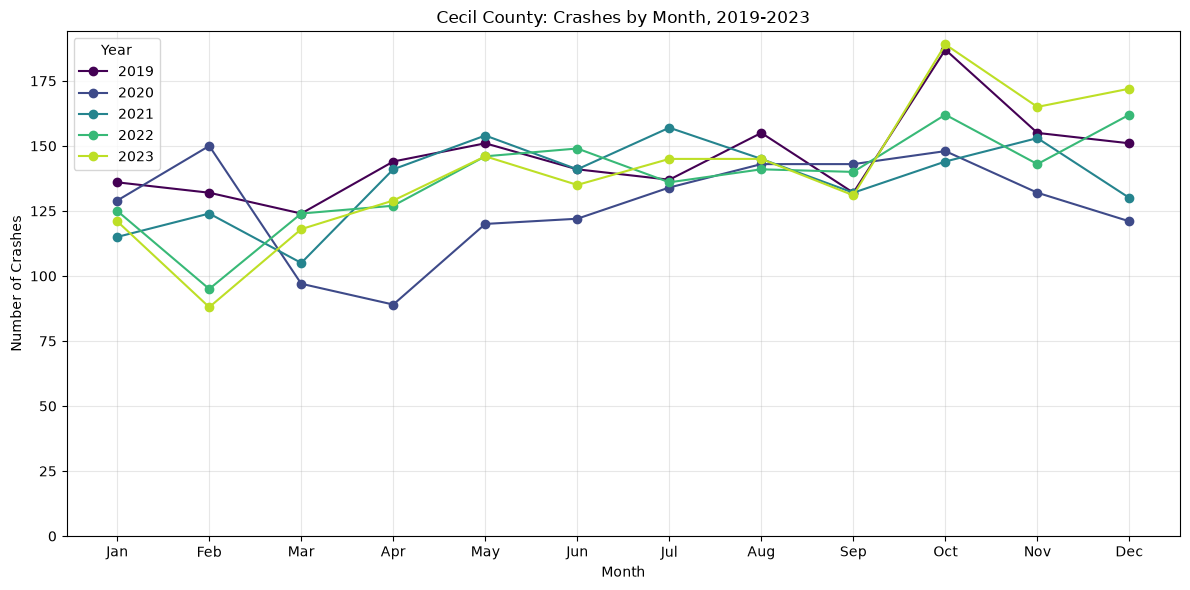

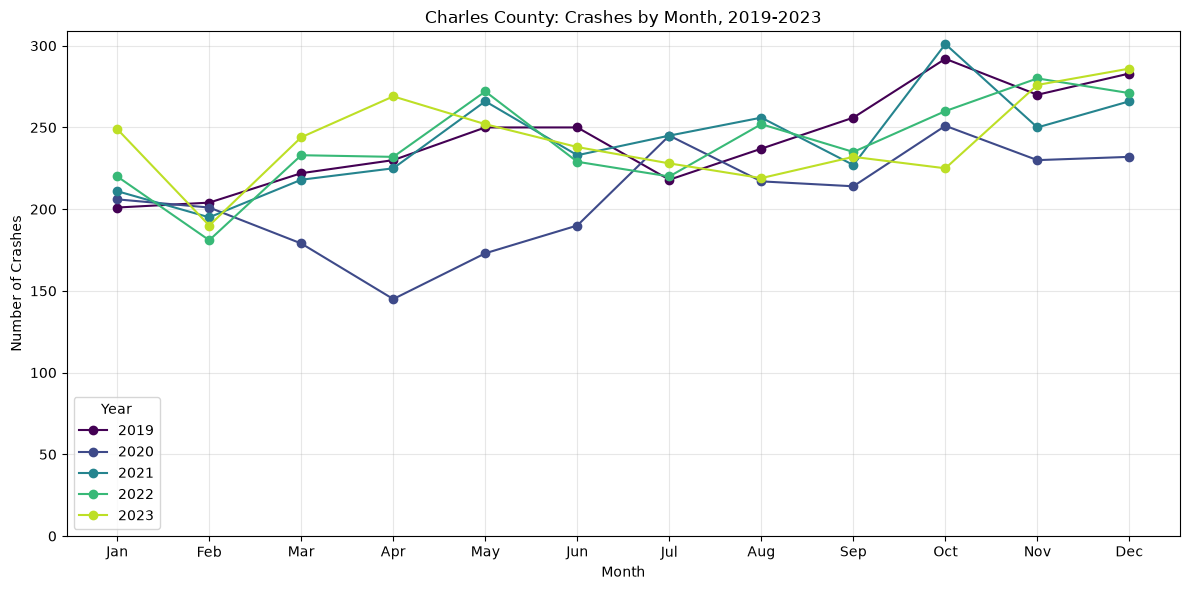

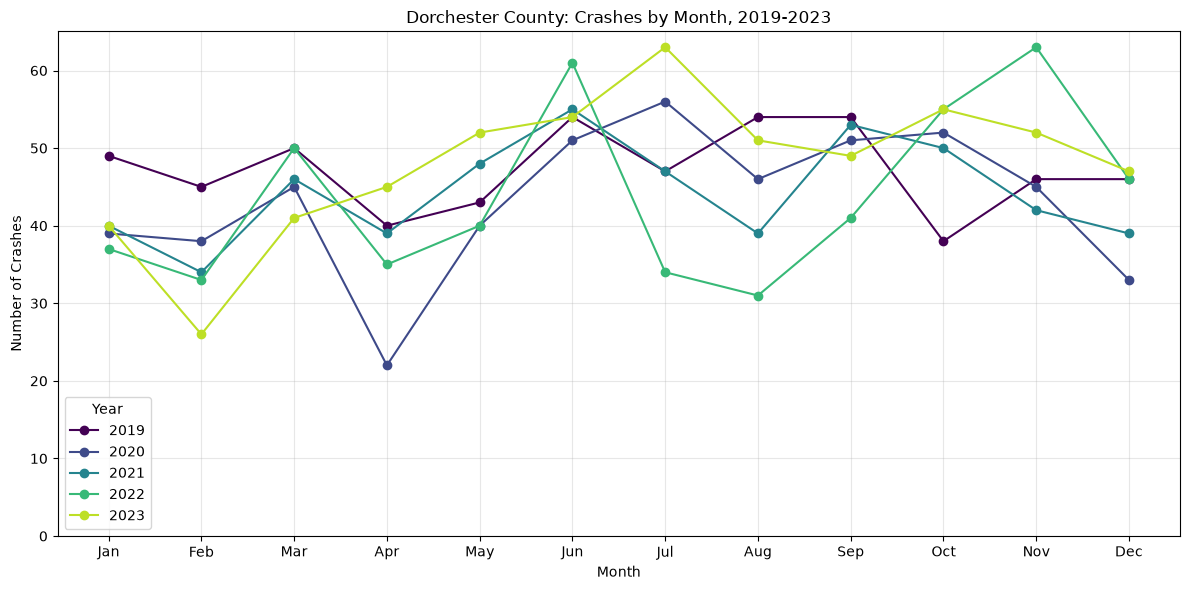

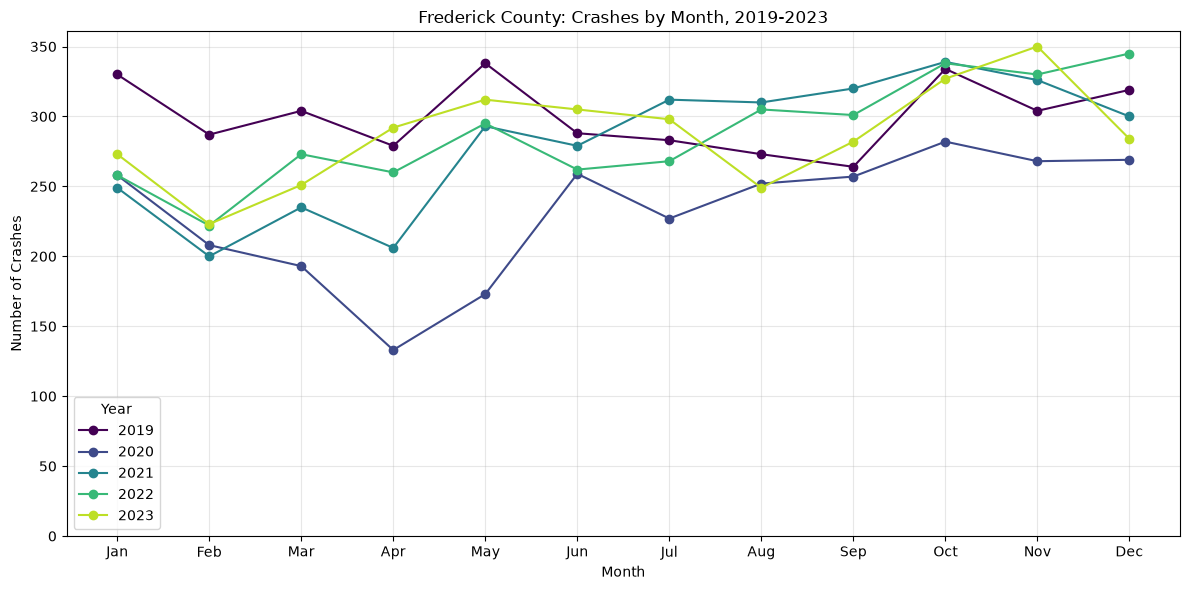

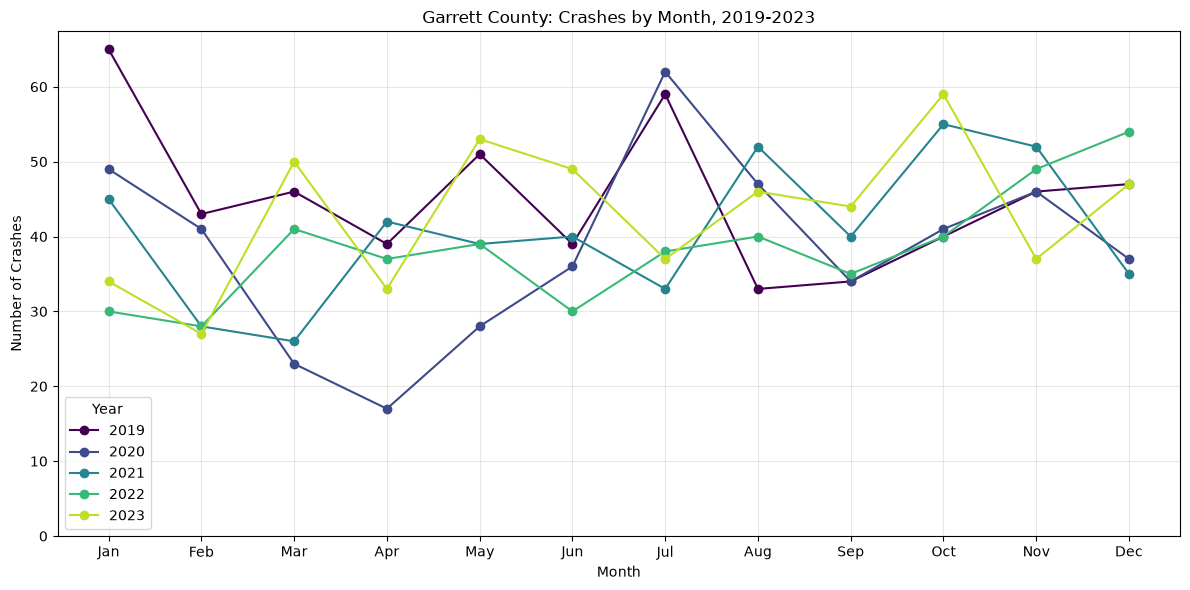

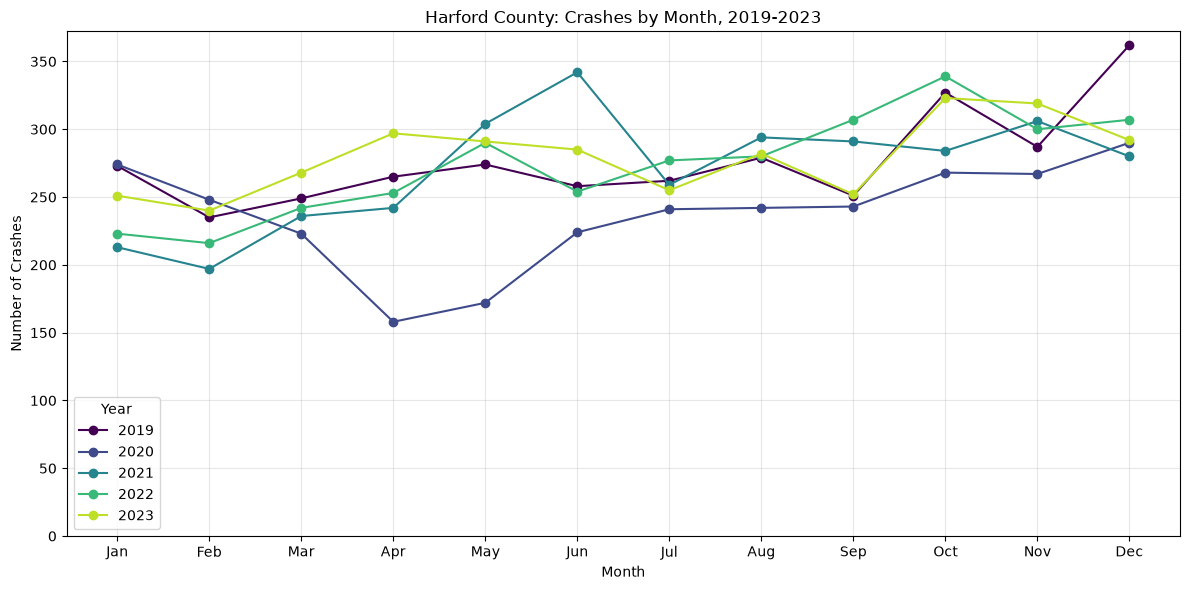

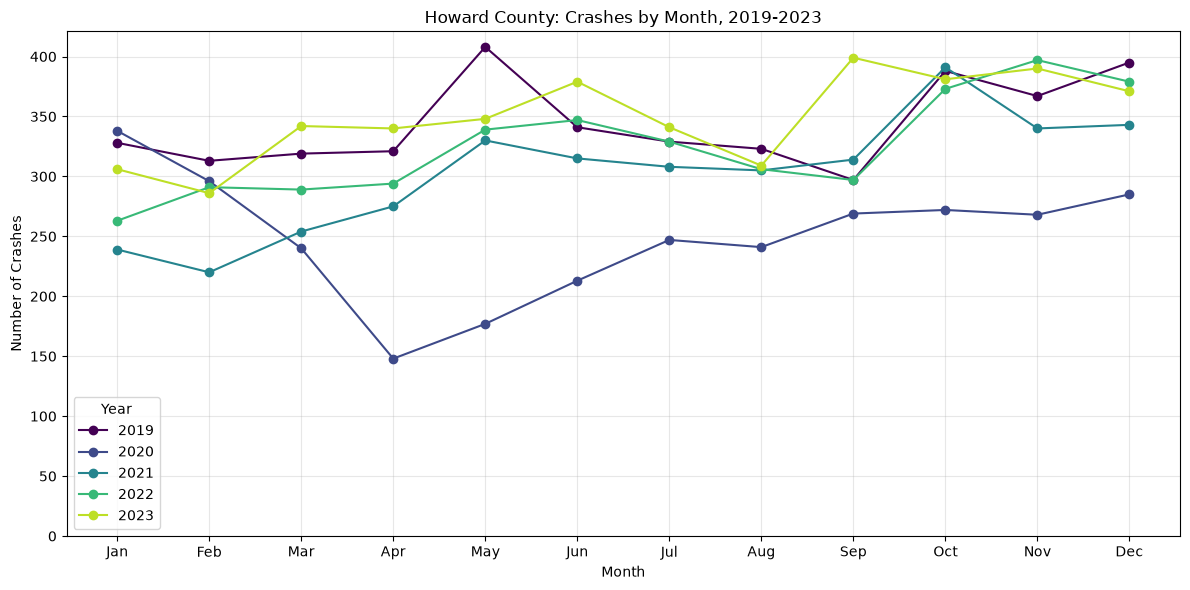

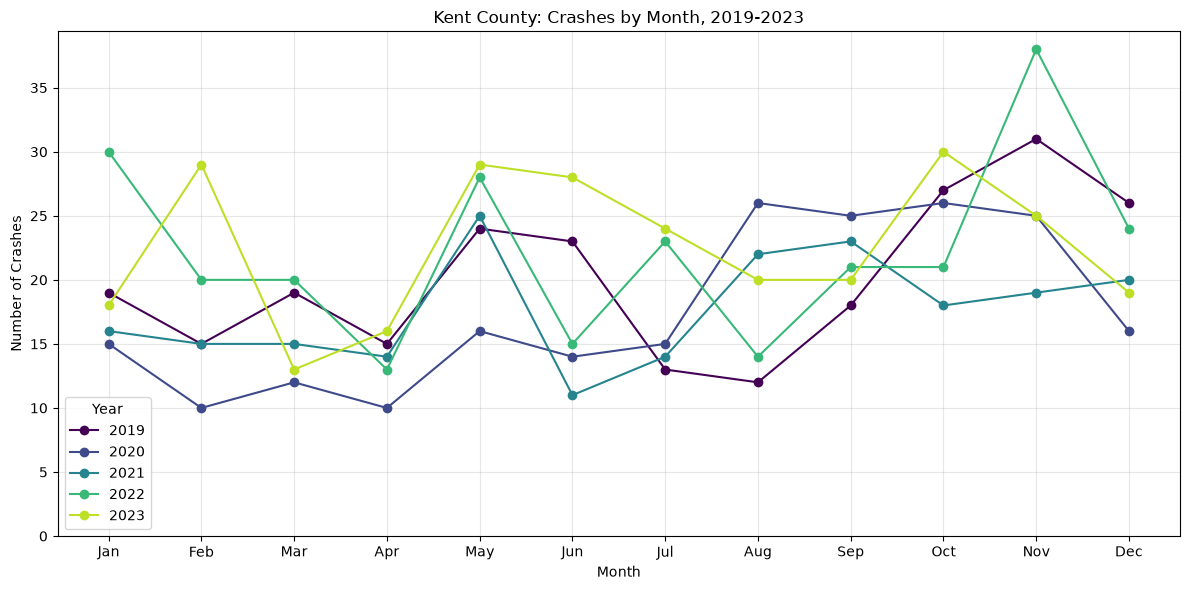

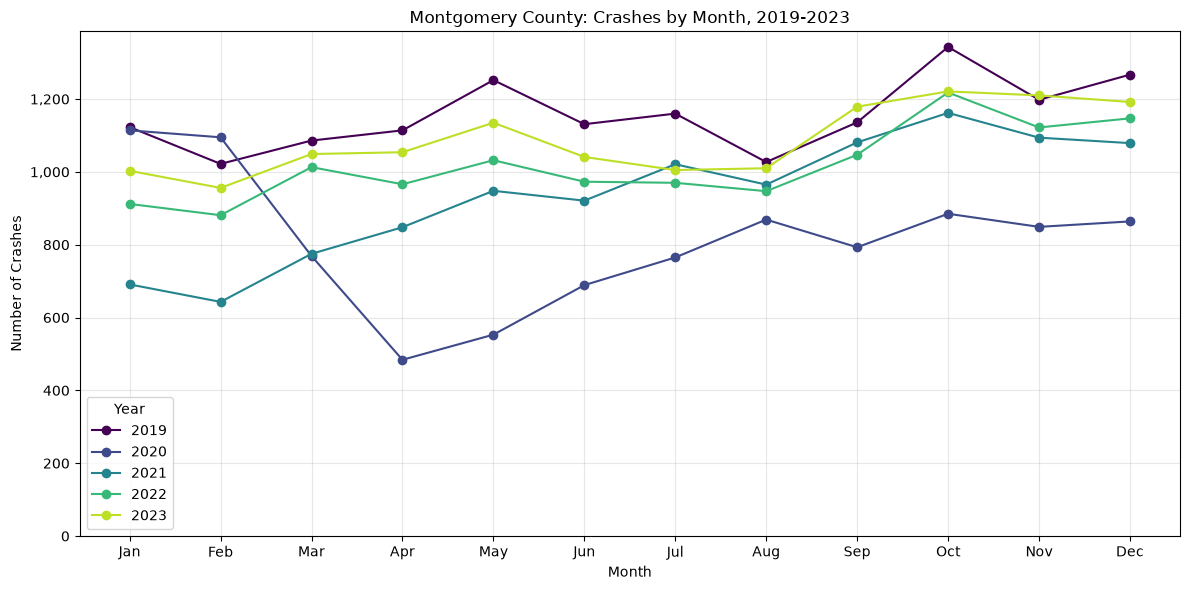

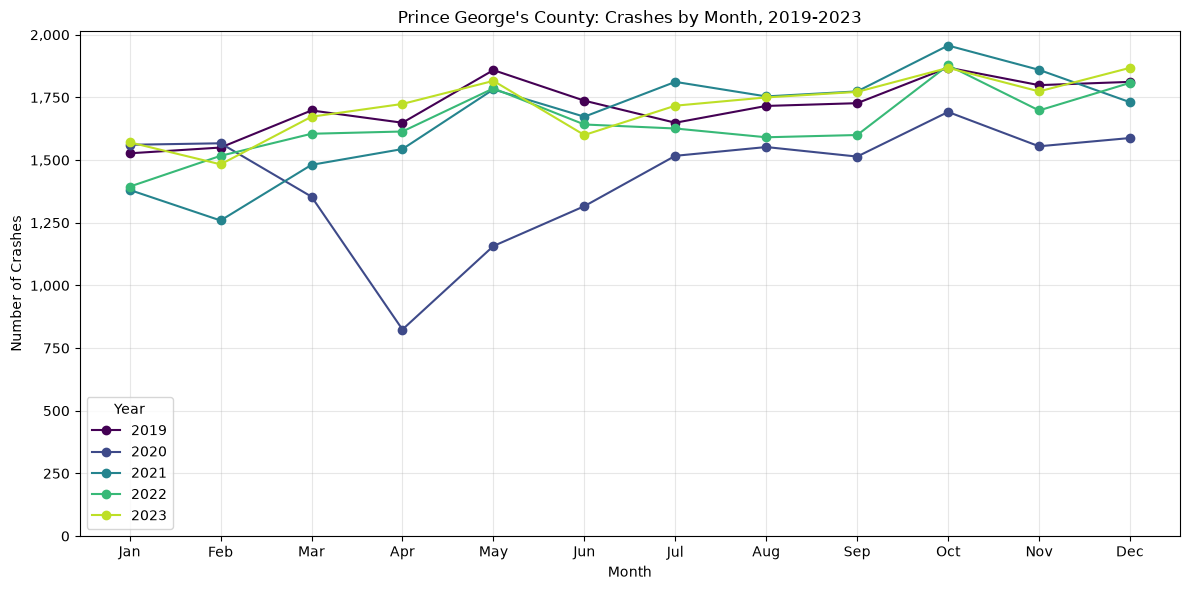

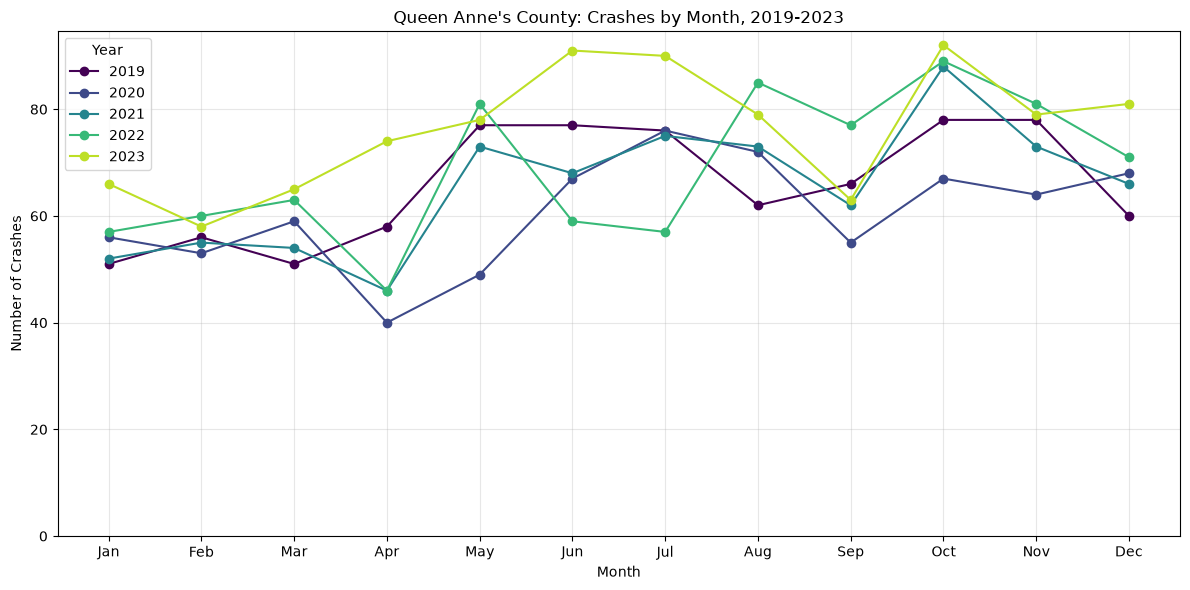

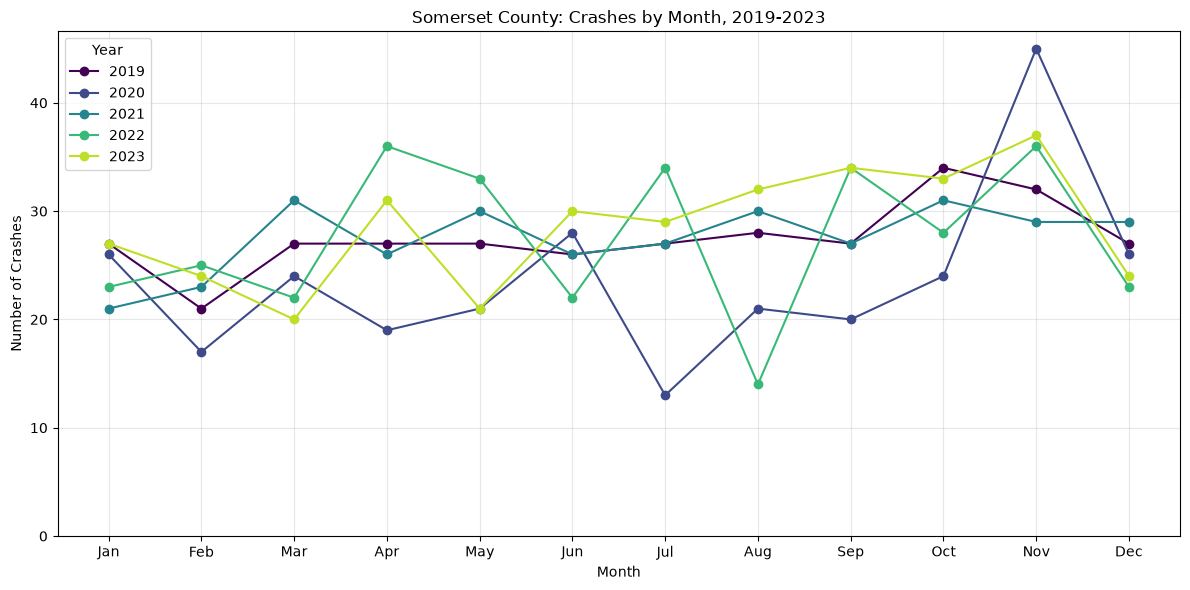

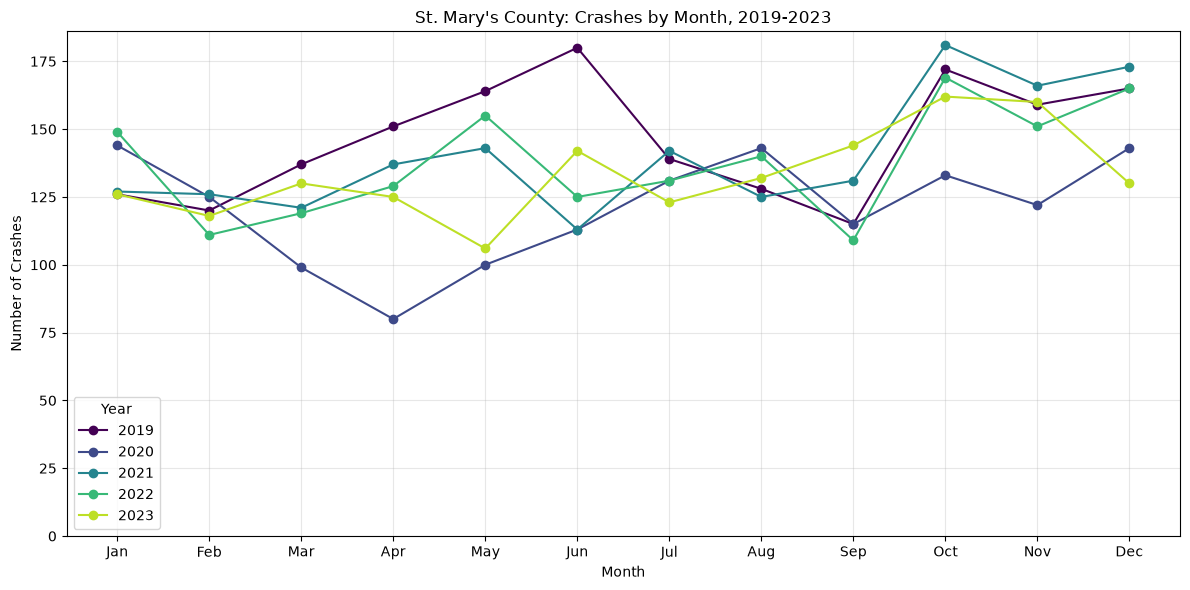

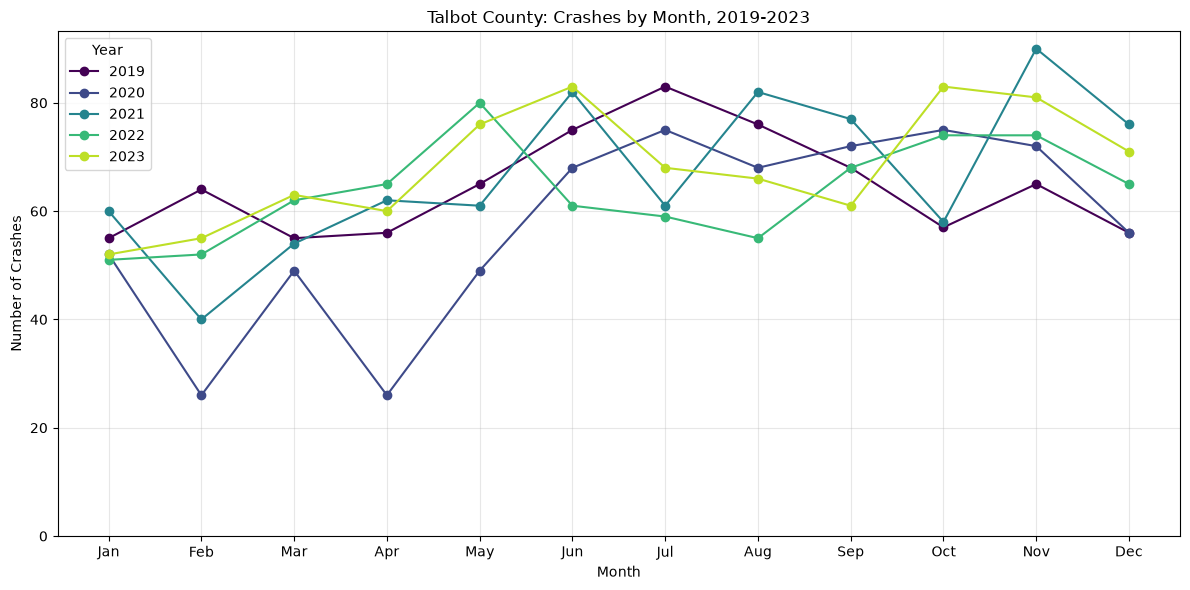

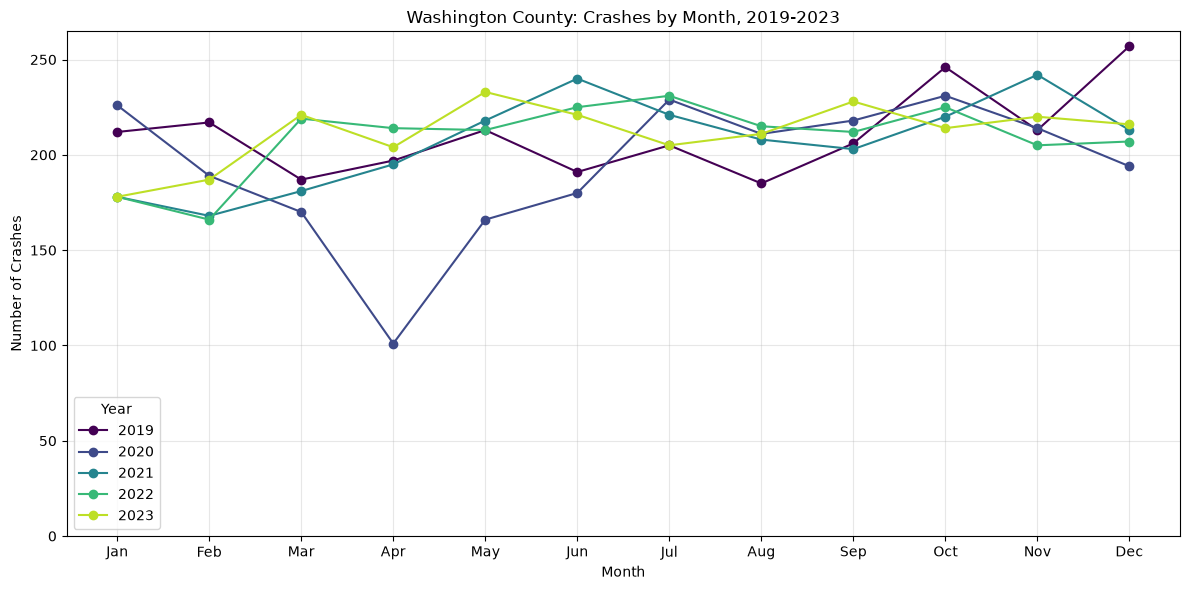

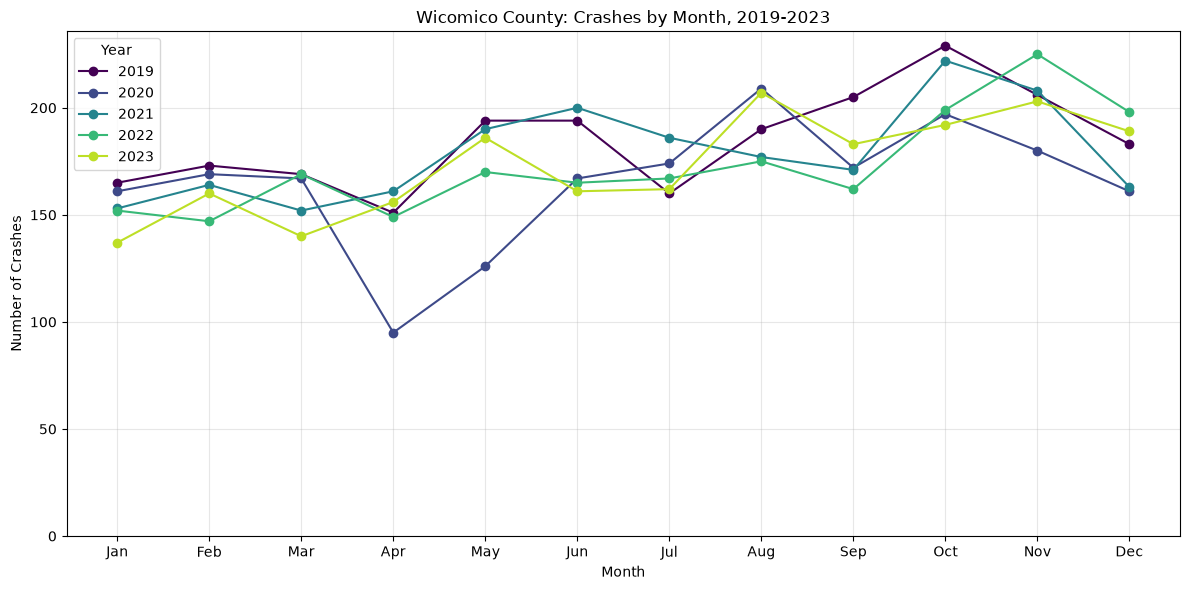

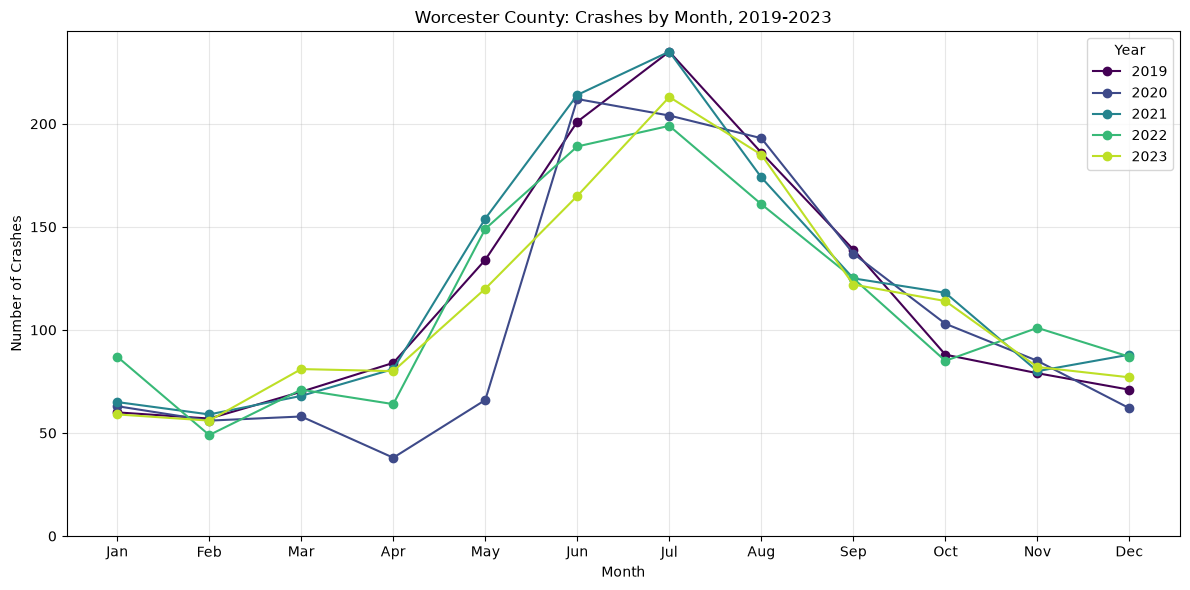

In [34]:
#Crash data by county for year range
import os                                      
os.makedirs("crash_charts", exist_ok=True)  

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def county_monthly_chart(county, filename=None):
    d = monthly[monthly["county"] == county]
    pivot = d.pivot(index="month", columns="year", values="total_crashes")   # 12 rows x 5 years

    fig, ax = plt.subplots(figsize=(12, 6))
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(pivot.columns)))
    for color, yr in zip(colors, pivot.columns):
        ax.plot(pivot.index, pivot[yr], marker="o", label=str(yr), color=color)

    ax.set_title(f"{county} County: Crashes by Month, 2019-2023")
    ax.set_xlabel("Month")
    ax.set_ylabel("Number of Crashes")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTHS)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
    ax.legend(title="Year")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

    plt.tight_layout()
    if filename is None:
        filename = f"monthly_crashes_{county.replace(' ', '_').replace(chr(39), '')}.png"
    plt.savefig(os.path.join("crash_charts", filename), dpi=200)
    plt.show()
    plt.close(fig)


for c in sorted(monthly["county"].unique()):
    county_monthly_chart(c)

In [22]:
#population tables
tla = pd.read_excel("maryland_crash_data/raw/County-table1A.xlsx", header=None)

counties = sorted(monthly["county"].unique())   # moved up

#data copied from pdf from planning.maryland.gov
vals_2019 = {
    "Allegany": 68575,
    "Anne Arundel": 585330,
    "Baltimore": 853764,
    "Baltimore City": 591876,
    "Calvert": 92431,
    "Caroline": 33306,
    "Carroll": 172278,
    "Cecil": 103381,
    "Charles": 165794,
    "Dorchester": 32461,
    "Frederick": 267598,
    "Garrett": 28947,
    "Harford": 259590,
    "Howard": 330064,
    "Kent": 19347,
    "Montgomery": 1060001,
    "Prince George's": 963706,
    "Queen Anne's": 49504,
    "Somerset": 24811,
    "St. Mary's": 113109,
    "Talbot": 37610,
    "Washington": 154341,
    "Wicomico": 103608,
    "Worcester": 52337,
}

pop_2019 = pd.DataFrame({
    "county": list(vals_2019.keys()),
    "year": 2019,
    "population": list(vals_2019.values()),
})

#2020-2023 from Table 1A
sub = tla[[0, 2, 3, 4, 5]].copy()
sub.columns = ["county", 2020, 2021, 2022, 2023]
sub["county"] = sub["county"].astype(str).str.replace(" County", "", regex=False).str.strip()
sub = sub[sub["county"].isin(counties)]

print(len(sub))                                 
print(set(counties) - set(sub["county"]))        
print(set(counties) - set(pop_2019["county"]))   
print(set(pop_2019["county"]) - set(counties))   

pop_2020_23 = sub.melt(id_vars="county", var_name="year", value_name="population")
pop_2020_23["population"] = pd.to_numeric(pop_2020_23["population"])
pop_2020_23["year"] = pop_2020_23["year"].astype(int)

print(pop_2019["population"].sum())              

#combine 2019 with 2020-2023 data
pop = pd.concat([pop_2019, pop_2020_23], ignore_index=True)
pop["year"] = pop["year"].astype(int)

print(pop.shape)                                 
print(pop.groupby("year")["population"].sum())
print(pop.pivot(index="county", columns="year", values="population"))

pop.to_csv("maryland_crash_data/md_population.csv", index=False)

24
set()
set()
set()
6163769
(120, 3)
year
2019    6163769
2020    6177935
2021    6179403
2022    6192440
2023    6217062
Name: population, dtype: int64
year                2019     2020     2021     2022     2023
county                                                      
Allegany           68575    67950    67671    67241    67296
Anne Arundel      585330   593412   596354   598751   599965
Baltimore         853764   853338   850670   848873   848676
Baltimore City    591876   583189   576575   570663   567517
Calvert            92431    92921    94249    94652    94828
Caroline           33306    33277    33443    33539    33838
Carroll           172278   172910   174282   175569   176735
Cecil             103381   103805   104073   104939   105676
Charles           165794   166692   168822   170376   172268
Dorchester         32461    32523    32590    32599    32922
Frederick         267598   272787   280666   288316   294154
Garrett            28947    28797    28766    28619  

In [32]:
from scipy.stats import pearsonr, spearmanr

county_totals = monthly.groupby("county")["total_crashes"].sum()
avg_pop = pop.groupby("county")["population"].mean()
cdf = pd.concat([county_totals, avg_pop], axis=1).reset_index()

print(cdf["total_crashes"].sum())    # 539842
print(cdf.sort_values("total_crashes", ascending=False).head(5))

r, p_r = pearsonr(cdf["population"], cdf["total_crashes"])
rho, p_s = spearmanr(cdf["population"], cdf["total_crashes"])
print(f"Pearson r = {r:.3f} (p = {p_r:.4g})")
print(f"Spearman rho = {rho:.3f} (p = {p_s:.4g})")


539842
             county  total_crashes  population
2         Baltimore         100876    851064.2
16  Prince George's          98172    959169.8
3    Baltimore City          84181    577964.0
15       Montgomery          60099   1061494.6
1      Anne Arundel          47896    594762.4
Pearson r = 0.922 (p = 1.595e-10)
Spearman rho = 0.974 (p = 1.163e-15)


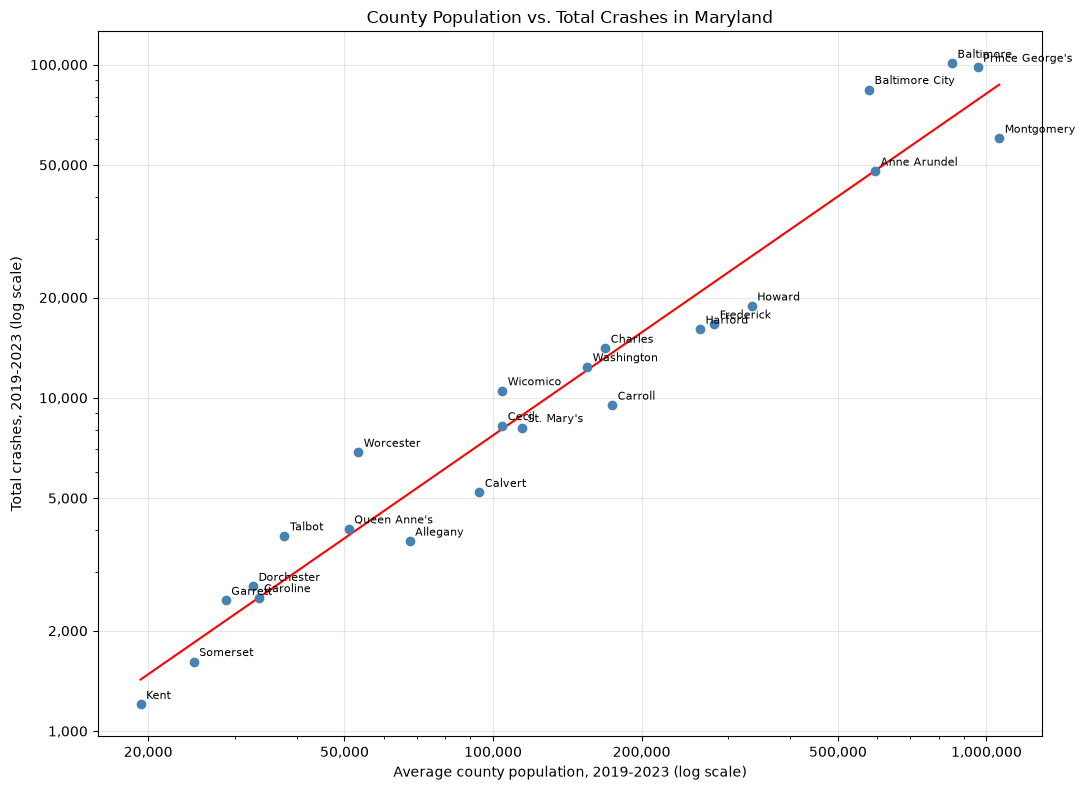

In [33]:
#correlation between amount of residents and crashes
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
from adjustText import adjust_text

fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(cdf["population"], cdf["total_crashes"], color="steelblue", zorder=3)


ax.set_xscale("log")
ax.set_yscale("log")

xticks = [20_000, 50_000, 100_000, 200_000, 500_000, 1_000_000]
yticks = [1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000]
ax.xaxis.set_major_locator(FixedLocator(xticks))
ax.yaxis.set_major_locator(FixedLocator(yticks))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{int(y):,}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_formatter(NullFormatter())


slope, intercept = np.polyfit(np.log10(cdf["population"]), np.log10(cdf["total_crashes"]), 1)
xs = np.linspace(cdf["population"].min(), cdf["population"].max(), 100)
ax.plot(xs, 10 ** (intercept + slope * np.log10(xs)), color="red", zorder=2)



for _, row in cdf.iterrows():
    ax.annotate(row["county"], (row["population"], row["total_crashes"]),
                xytext=(4, 4), textcoords="offset points", fontsize=8)

ax.set_xlabel("Average county population, 2019-2023 (log scale)")
ax.set_ylabel("Total crashes, 2019-2023 (log scale)")
ax.set_title("County Population vs. Total Crashes in Maryland")
ax.grid(alpha=0.3, which="major")
plt.tight_layout()
plt.savefig("population_vs_crashes.png", dpi=200)
plt.show()